# AAL Sales Analysis Report - Q4 2020
AAL, established in 2000, is a well-known brand in Australia, particularly recognized for its clothing business. It has opened branches in various states, metropolises, and tier-1 and tier-2 cities across the country.
#The brand caters to all age groups, from kids to the elderly.
#Currently experiencing a surge in business, AAL is actively pursuing expansion opportunities. To facilitate informed investment decisions, the CEO has assigned the responsibility to the head of AAL’s sales and marketing (S&M) department. The specific tasks include:
1)	Identify the states that are generating the highest revenues.
2)	Develop sales programs for states with lower revenues. The head of sales and marketing has requested your assistance with this task.
Analyze the sales data of the company for the fourth quarter in Australia, examining it on a state-by-state basis. Provide insights to assist the company in making data-driven decisions for the upcoming year.


## 1. Data Wrangling
a.	Ensure that the data is clean and free from any missing or incorrect entries.
    ○	Inspect the data manually to identify missing or incorrect information using the functions isna() and notna().
b.	Based on your knowledge of data analytics, include your recommendations for treating missing and incorrect data (dropping the null values or filling them).
c.	Choose a suitable data wrangling technique—either data standardization or normalization. Execute the preferred normalization method and present the resulting data. (Normalization is the preferred approach for this problem.)
d.	Share your insights regarding the application of the GroupBy() function for either data chunking or merging, and offer a recommendation based on your analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('datasets/AusApparalSales4thQrt2020.csv')
data.head()


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


In [3]:
# Missing values and duplicates
print(data.isna().sum())
print(data.notna().sum())
print('Duplicates:', data.duplicated().sum())


Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64
Date     7560
Time     7560
State    7560
Group    7560
Unit     7560
Sales    7560
dtype: int64
Duplicates: 0


In [5]:
# Manual Min-Max Normalization
data_normalized = data.copy()
numeric_cols = data.select_dtypes(include=np.number).columns

for col in numeric_cols:
    data_normalized[col] = (data[col]-data[col].min())/(data[col].max()-data[col].min())

data_normalized.head()


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,0.095238,0.095238
1,1-Oct-2020,Morning,WA,Men,0.095238,0.095238
2,1-Oct-2020,Morning,WA,Women,0.031746,0.031746
3,1-Oct-2020,Morning,WA,Seniors,0.206349,0.206349
4,1-Oct-2020,Afternoon,WA,Kids,0.015873,0.015873


## 2. Data Analysis
a.	Perform descriptive statistical analysis on the data in the Sales and Unit columns. Utilize techniques such as mean, median, mode, and standard deviation for this analysis.
b.	Identify the group with the highest sales and the group with the lowest sales based on the data provided.
c.	Identify the group with the highest and lowest sales based on the data provided.
d.	Generate weekly, monthly, and quarterly reports to document and present the results of the analysis conducted.
(Use suitable libraries such as NumPy, Pandas, and SciPy for performing the analysis.)


In [6]:
# Descriptive statistics
for col in ['Sales','Unit']:
    print('\n', col)
    print('Mean:', data[col].mean())
    print('Median:', data[col].median())
    print('Mode:', data[col].mode()[0])
    print('Std Dev:', data[col].std())



 Sales
Mean: 45013.5582010582
Median: 35000.0
Mode: 22500
Std Dev: 32253.506943966073

 Unit
Mean: 18.00542328042328
Median: 14.0
Mode: 9
Std Dev: 12.90140277758643


In [7]:
group_sales = data.groupby('Group')['Sales'].sum()
print(group_sales)
print('Highest:', group_sales.idxmax())
print('Lowest:', group_sales.idxmin())


Group
Kids       85072500
Men        85750000
Seniors    84037500
Women      85442500
Name: Sales, dtype: int64
Highest:  Men
Lowest:  Seniors


In [8]:
data['Date'] = pd.to_datetime(data['Date'])

weekly_report = data.groupby(pd.Grouper(key='Date', freq='W')).agg({'Sales':'sum','Unit':'sum'})
monthly_report = data.groupby(pd.Grouper(key='Date', freq='ME')).agg({'Sales':'sum','Unit':'sum'})
quarterly_report = data.groupby(pd.Grouper(key='Date', freq='QE')).agg({'Sales':'sum','Unit':'sum'})

weekly_report.head()


,Sales,Unit
Date,,
2020-10-04,15045000,6018
2020-10-11,27002500,10801
2020-10-18,26640000,10656
2020-10-25,26815000,10726
2020-11-01,21807500,8723


## 3. Data Visualization
a.	Use suitable data visualization libraries to construct a dashboard for the head of sales and marketing. The dashboard should encompass key parameters:
o	State-wise sales analysis for different demographic groups (kids, women, men, and seniors).
o	Group-wise sales analysis (Kids, Women, Men, and Seniors) across various states.
o	Time-of-the-day analysis: Identify peak and off-peak sales periods to facilitate strategic planning for S&M teams. This information aids in designing programs like hyper-personalization and Next Best Offers to enhance sales.
b.	Ensure the visualization is clear and accessible for effective decision-making by the head of sales and marketing (S&M).
The dashboard must contain daily, weekly, monthly, and quarterly charts.
(Any visualization library can be used for this purpose. However, since statistical analysis is being done, Seaborn is preferred.)
c.	Include your recommendation and indicate why you are choosing the recommended visualization package.


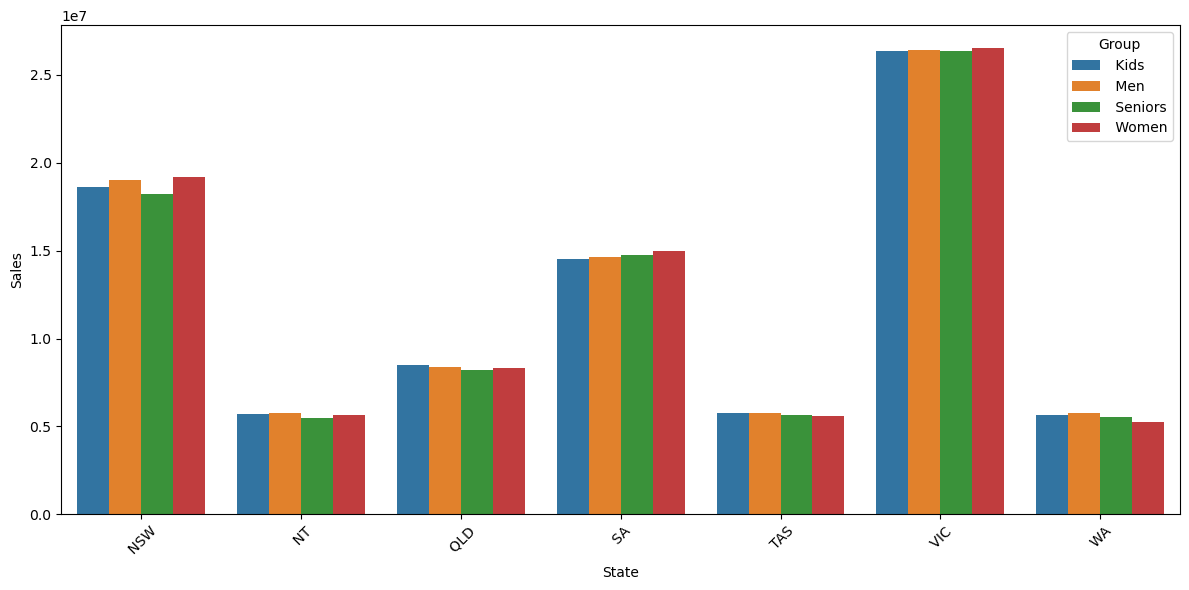

In [9]:
state_group_sales = data.groupby(['State','Group'])['Sales'].sum().reset_index()

plt.figure(figsize=(12,6))
sns.barplot(data=state_group_sales,x='State',y='Sales',hue='Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


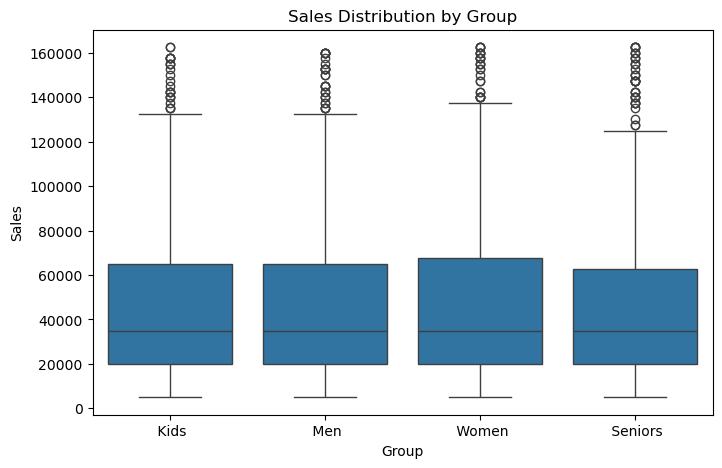

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(data=data,x='Group',y='Sales')
plt.title('Sales Distribution by Group')
plt.show()


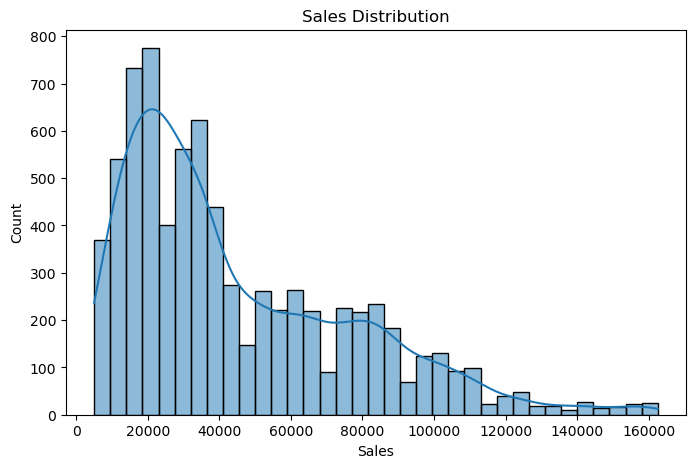

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(data['Sales'], kde=True)
plt.title('Sales Distribution')
plt.show()


## 4. Report Generation

a)	Use JupyterLab Notebook for generating reports, which includes tasks such as data wrangling, analysis, and visualization. Please note that JupyterLab enables you to integrate code seamlessly with graphs and plots.
b)	Use Markdown in suitable places while presenting your report. 
c)	Use suitable graphs, plots, and analysis reports in the report, along with recommendations. Note that various aspects of analysis require different graphs and plots.
○	Use a box plot for descriptive statistics.
○	Use the Seaborn distribution plot for any other statistical plotting.

